# 02 — EDA, Outlier & Penyusunan Dataset Model (v3)

Input: tabel fakta bersih dari notebook 01. Output:

| file | isi | dipakai oleh |
|---|---|---|
| `panel_kab_tahun.parquet` | kabupaten × tahun (semua tahun KKP yang valid), **boleh ada NaN** per kolom | regresi produksi & forecast, notebook 05 |
| `features_kab.parquet` | 1 baris per kabupaten (profil seluruh tahun valid) | clustering |
| `reg_komoditas.parquet` | kab × komoditas × tahun (kunci unik) | regresi nilai |
| `feature_registry.csv` | **fitur apa yang boleh dipakai model** (otomatis dari cakupan data) | notebook 03 & 04 |

**Beda dari v2:** tidak ada `38×5`, tahun 2024, atau "Sumenep" yang ditulis keras. Jumlah tahun/kabupaten mengikuti data; luas lahan & RTP **ikut masuk panel** dan dipakai model *hanya bila cakupannya memadai* (aturan di `feature_registry`).

In [1]:
import os, json, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression

PROC = Path('../data/processed'); REP = Path('../output/reports'); FIG = Path('../output/figures'); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50); pd.set_option('display.max_rows', 100)

fp  = pd.read_parquet(PROC / 'fact_pembesaran.parquet');  fpm = pd.read_parquet(PROC / 'fact_pembudidaya.parquet')
frt = pd.read_parquet(PROC / 'fact_rtp.parquet');         fj  = pd.read_parquet(PROC / 'fact_jenis_budidaya.parquet')
fpb = pd.read_parquet(PROC / 'fact_pembenihan.parquet');  fhs = pd.read_parquet(PROC / 'fact_ikanhias.parquet')
fl  = pd.read_parquet(PROC / 'fact_luas.parquet');        bps = pd.read_parquet(PROC / 'bps_totals.parquet')
fp = fp[fp.vol_ton.notna()]
YEARS = sorted(int(y) for y in fp.tahun.unique()); KABS = sorted(fp.kabupaten.unique())
print(f'KKP kanonik: {len(KABS)} kabupaten | tahun {YEARS} | {len(fp)} baris')

KKP kanonik: 38 kabupaten | tahun [2020, 2021, 2022, 2023, 2024] | 1567 baris


## 1. Panel kabupaten × tahun
`NaN` berarti *tidak ada data yang bisa dipercaya* (bukan nol). Baris kab-tahun tanpa produksi KKP tidak masuk panel.

In [2]:
smin = lambda s: s.sum(min_count=1)
g = fp.groupby(['kabupaten', 'tahun']).agg(produksi_ton=('vol_ton', smin), nilai_juta=('nilai_juta', smin), n_komoditas=('komoditas', 'nunique')).reset_index()
g = g[g.produksi_ton > 0].copy()
g['harga_rp_kg'] = np.where((g.produksi_ton > 0) & (g.nilai_juta > 0), g.nilai_juta * 1000 / g.produksi_ton, np.nan)

sh = fp.pivot_table(index=['kabupaten', 'tahun'], columns='grup', values='vol_ton', aggfunc='sum', fill_value=0)
pr = sh.div(sh.sum(axis=1), axis=0); ent = -(pr * np.log(pr.where(pr > 0))).sum(axis=1)
shr = pr.add_prefix('share_').assign(shannon=ent, top_share=pr.max(axis=1)).reset_index()
g = g.merge(shr, on=['kabupaten', 'tahun'], how='left')

g = g.merge(fpm[['kabupaten', 'tahun', 'pembudidaya_clean', 'flag_lonjakan']].rename(columns={'pembudidaya_clean': 'pembudidaya'}), on=['kabupaten', 'tahun'], how='left')
g = g.merge(frt[['kabupaten', 'tahun', 'rtp']], on=['kabupaten', 'tahun'], how='left')
g = g.merge(fl[['kabupaten', 'tahun', 'luas_lahan_ha', 'luas_sumber']], on=['kabupaten', 'tahun'], how='left')
pm = fj.groupby(['kabupaten', 'tahun'])['produksi_ton'].sum(min_count=1).rename('produksi_media_ton').reset_index()
g = g.merge(pm, on=['kabupaten', 'tahun'], how='left')
g['flag_lonjakan'] = g.flag_lonjakan.fillna(False).astype(bool)
for c in ['pembudidaya', 'rtp', 'luas_lahan_ha', 'produksi_media_ton']: g[c] = pd.to_numeric(g[c], errors='coerce')     # sumber opsional yang tidak ada -> kolom NaN bertipe float
g = g.sort_values(['kabupaten', 'tahun']).reset_index(drop=True)

pos = lambda s: s.where(s > 0)
for c in ['produksi_ton', 'nilai_juta', 'pembudidaya', 'harga_rp_kg']: g['l_' + c] = np.log(pos(g[c]))
g['l_luas'] = np.log(pos(g.luas_lahan_ha)); g['l_rtp'] = np.log(pos(g.rtp))
g['prod_per_pembudidaya'] = g.produksi_ton / pos(g.pembudidaya)
g['prod_per_ha'] = g.produksi_ton / pos(g.luas_lahan_ha)

# kesesuaian nama kabupaten antar sumber (nama beda = baris hilang diam-diam)
for nm, d in [('pembudidaya', fpm), ('rtp', frt), ('luas', fl), ('produksi_media', pm)]:
    miss = sorted(set(KABS) - set(d.kabupaten)); extra = sorted(set(d.kabupaten) - set(KABS))
    print(f'{nm:15s} kab KKP tak ditemukan di sumber ini: {miss if miss else "-"} | kab sumber ini yang tak ada di KKP: {extra if extra else "-"}')
print('Panel:', g.shape, '| duplikat (kab,tahun):', int(g.duplicated(['kabupaten', 'tahun']).sum()))
g.head()

pembudidaya     kab KKP tak ditemukan di sumber ini: - | kab sumber ini yang tak ada di KKP: -
rtp             kab KKP tak ditemukan di sumber ini: - | kab sumber ini yang tak ada di KKP: -
luas            kab KKP tak ditemukan di sumber ini: - | kab sumber ini yang tak ada di KKP: -
produksi_media  kab KKP tak ditemukan di sumber ini: - | kab sumber ini yang tak ada di KKP: -
Panel: (190, 31) | duplikat (kab,tahun): 0


,kabupaten,tahun,produksi_ton,nilai_juta,n_komoditas,harga_rp_kg,share_bandeng,share_gurami,share_lainnya,share_lele,share_mas,share_nila,share_patin,share_rumput_laut,share_udang,shannon,top_share,pembudidaya,flag_lonjakan,rtp,luas_lahan_ha,luas_sumber,produksi_media_ton,l_produksi_ton,l_nilai_juta,l_pembudidaya,l_harga_rp_kg,l_luas,l_rtp,prod_per_pembudidaya,prod_per_ha
0,Bangkalan,2020,7060.62,237491.0,8,33635.997972,0.299492,0.0,0.265725,0.059396,0.0,0.005212,0.0,0.00000,0.370176,1.276228,0.370176,1390.0,False,1246.0,NaN,None,7060.506,8.862288,12.377885,7.237059,10.423352,NaN,7.127694,5.079583,NaN
1,Bangkalan,2021,7951.91,273601.0,8,34406.953801,0.286195,0.0,0.298713,0.042661,0.0,0.006193,0.0,0.00000,0.366237,1.252919,0.366237,1510.0,False,1040.0,NaN,None,7951.914,8.981167,12.519426,7.319865,10.446014,NaN,6.946976,5.266166,NaN
2,Bangkalan,2022,8244.38,256200.0,7,31075.714608,0.348007,0.0,0.364984,0.039215,0.0,0.015696,0.0,0.00000,0.232099,1.266412,0.364984,1380.0,False,1407.0,NaN,None,8327.000,9.017287,12.453714,7.229839,10.344182,NaN,7.249215,5.974188,NaN
3,Bangkalan,2023,9764.37,344648.0,7,35296.491223,0.317286,0.0,0.331530,0.041651,0.0,0.006810,0.0,0.00000,0.302722,1.258350,0.331530,1433.0,False,1375.0,NaN,None,11564.370,9.186495,12.750279,7.267525,10.471539,NaN,7.226209,6.813936,NaN
4,Bangkalan,2024,11966.54,396710.0,10,33151.604390,0.354639,0.0,0.365068,0.032683,0.0,0.009389,0.0,0.00005,0.238172,1.233357,0.365068,1424.0,False,NaN,NaN,None,NaN,9.389870,12.890961,7.261225,10.408846,NaN,NaN,8.403469,NaN


### 1b. Registri fitur — siapa yang boleh dipakai model?
Aturan (otomatis, dihitung ulang setiap data bertambah):
* `usable_cluster`: ≥ **80% kabupaten** punya minimal satu tahun valid;
* `usable_panel`: ≥ **60% baris kab-tahun** terisi.
Fitur yang tidak lolos tetap tampil di dashboard (selama datanya ada), hanya tidak dimasukkan ke model.

In [3]:
CAND = ['pembudidaya', 'rtp', 'luas_lahan_ha', 'harga_rp_kg', 'produksi_media_ton']
reg = pd.DataFrame({'fitur': CAND,
    'kab_cover':  [g.groupby('kabupaten')[c].apply(lambda s: s.notna().any()).mean() for c in CAND],
    'row_cover':  [g[c].notna().mean() for c in CAND],
    'tahun_valid': [', '.join(str(y) for y in sorted(g.loc[g[c].notna(), 'tahun'].unique())) for c in CAND]})
reg['usable_cluster'] = reg.kab_cover >= 0.8; reg['usable_panel'] = reg.row_cover >= 0.6
reg.round(3).to_csv(REP / 'feature_registry.csv', index=False); display(reg.round(2))
cov_y = g.groupby('tahun')[CAND].agg(lambda s: s.notna().mean()).round(2); print('Cakupan kabupaten per tahun:'); display(cov_y)

,fitur,kab_cover,row_cover,tahun_valid,usable_cluster,usable_panel
0,pembudidaya,1.00,1.00,"2020, 2021, 2022, 2023, 2024",True,True
1,rtp,1.00,0.80,"2020, 2021, 2022, 2023",True,True
2,luas_lahan_ha,0.08,0.06,"2020, 2021, 2022, 2023, 2024",False,False
3,harga_rp_kg,1.00,1.00,"2020, 2021, 2022, 2023, 2024",True,True
4,produksi_media_ton,1.00,0.80,"2020, 2021, 2022, 2023",True,True


Cakupan kabupaten per tahun:


,pembudidaya,rtp,luas_lahan_ha,harga_rp_kg,produksi_media_ton
tahun,,,,,
2020,1.0,1.0,0.05,1.0,1.0
2021,1.0,1.0,0.03,1.0,1.0
2022,1.0,1.0,0.08,1.0,1.0
2023,1.0,1.0,0.08,1.0,1.0
2024,1.0,0.0,0.08,1.0,0.0


### 1c. Validasi total terhadap angka resmi BPS Jawa Timur
Baris `Jawa Timur` di file BPS adalah total resmi; total panel harus cocok.

In [4]:
tot = g.groupby('tahun')['produksi_ton'].sum().to_frame('panel_ton')
b = bps.drop_duplicates('tahun').set_index('tahun')['bps_jatim_ton'] if len(bps) else pd.Series(dtype=float)
tot['BPS_Jatim_ton'] = b; tot['selisih_%'] = ((tot.panel_ton / tot.BPS_Jatim_ton - 1) * 100).round(2); display(tot.round(0))
if tot['selisih_%'].abs().max() > 5: print('PERINGATAN: ada tahun dengan selisih >5% terhadap BPS -> periksa notebook 01 (qc_report.csv).')

,panel_ton,BPS_Jatim_ton,selisih_%
tahun,,,
2020,1264159.0,1264159.0,-0.0
2021,1279954.0,1279959.0,-0.0
2022,1284130.0,1284129.0,0.0
2023,1347520.0,496.0,271626.0
2024,1392702.0,697.0,199814.0


PERINGATAN: ada tahun dengan selisih >5% terhadap BPS -> periksa notebook 01 (qc_report.csv).


## 2. EDA

,produksi_ton,nilai_juta,n_kab,harga_rata_rp_kg
tahun,,,,
2020,1264159.0,17175258.0,38,13586.0
2021,1279954.0,18436087.0,38,14404.0
2022,1284130.0,19017325.0,38,14810.0
2023,1347520.0,19762024.0,38,14665.0
2024,1392702.0,19791862.0,38,14211.0


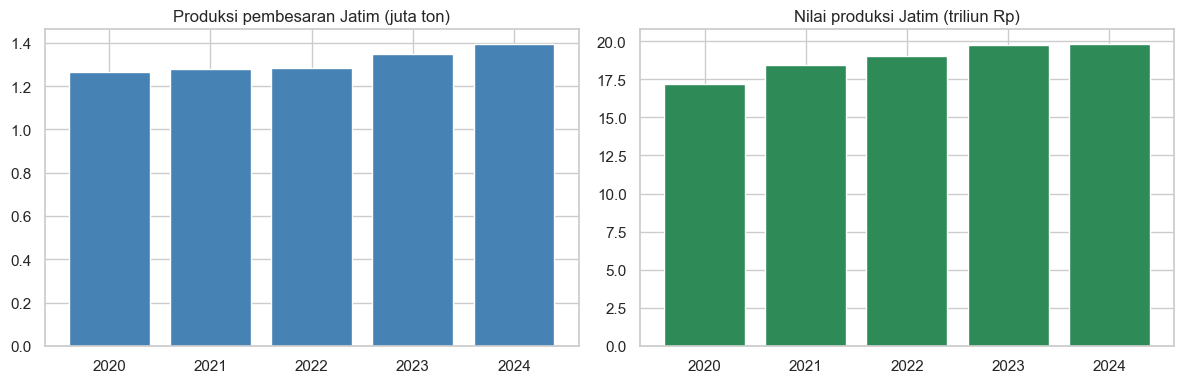

In [5]:
t = g.groupby('tahun').agg(produksi_ton=('produksi_ton', 'sum'), nilai_juta=('nilai_juta', 'sum'), n_kab=('kabupaten', 'nunique'))
t['harga_rata_rp_kg'] = t.nilai_juta * 1000 / t.produksi_ton; display(t.round(0))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(t.index, t.produksi_ton / 1e6, color='steelblue'); ax[0].set_title('Produksi pembesaran Jatim (juta ton)')
ax[1].bar(t.index, t.nilai_juta / 1e6, color='seagreen'); ax[1].set_title('Nilai produksi Jatim (triliun Rp)')
plt.tight_layout(); plt.savefig(FIG / '02_tren_provinsi.png', dpi=110); plt.show()

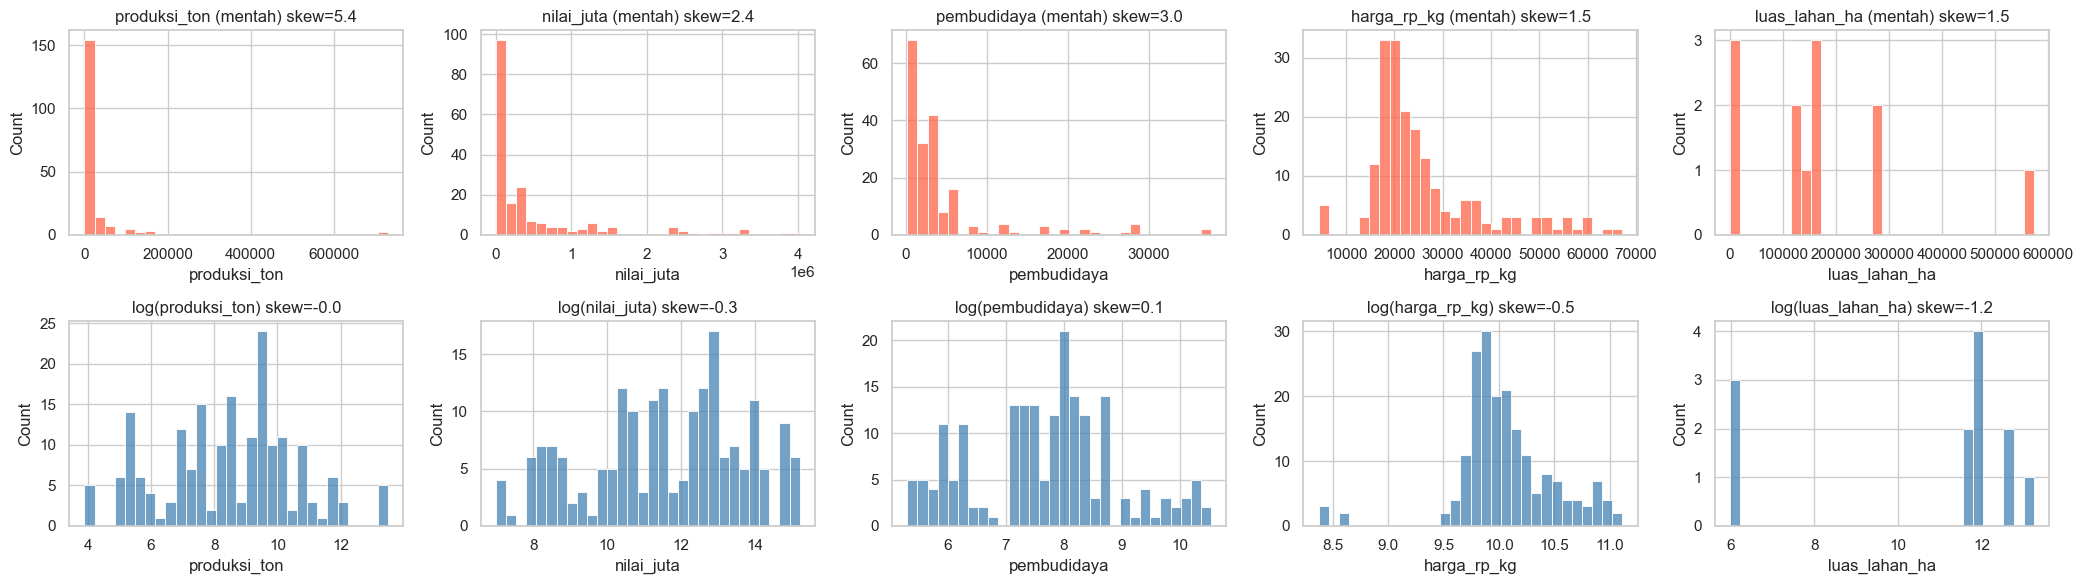

In [6]:
cols = [c for c in ['produksi_ton', 'nilai_juta', 'pembudidaya', 'harga_rp_kg', 'luas_lahan_ha'] if g[c].notna().sum() > 10]
fig, ax = plt.subplots(2, len(cols), figsize=(4.2 * len(cols), 6))
for i, c in enumerate(cols):
    x = g[c].dropna(); x = x[x > 0]
    sns.histplot(x, bins=30, ax=ax[0, i], color='tomato'); ax[0, i].set_title(f'{c} (mentah) skew={x.skew():.1f}')
    sns.histplot(np.log(x), bins=30, ax=ax[1, i], color='steelblue'); ax[1, i].set_title(f'log({c}) skew={np.log(x).skew():.1f}')
plt.tight_layout(); plt.savefig(FIG / '02_distribusi_mentah_vs_log.png', dpi=110); plt.show()

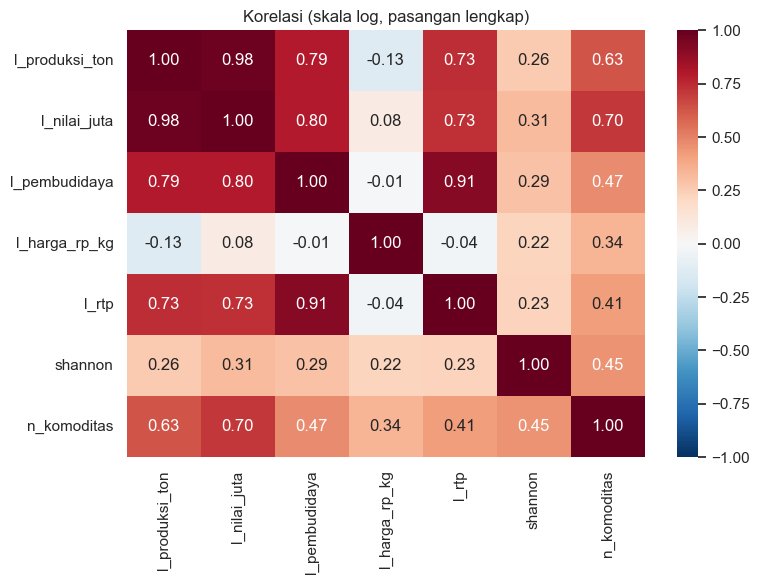

VIF pada 145 baris lengkap (['l_produksi_ton', 'l_pembudidaya', 'l_harga_rp_kg', 'l_rtp', 'shannon']):


,VIF
l_produksi_ton,2.77
l_pembudidaya,7.30
l_harga_rp_kg,1.11
l_rtp,6.02
shannon,1.15


VIF > 5 berarti fitur tumpang tindih -> jangan dimasukkan bersama ke model linear.


In [7]:
lc = [c for c in ['l_produksi_ton', 'l_nilai_juta', 'l_pembudidaya', 'l_harga_rp_kg', 'l_luas', 'l_rtp', 'shannon', 'n_komoditas'] if g[c].notna().sum() > 20]
plt.figure(figsize=(8, 6)); sns.heatmap(g[lc].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Korelasi (skala log, pasangan lengkap)'); plt.tight_layout(); plt.savefig(FIG / '02_korelasi_log.png', dpi=110); plt.show()

def vif(df):
    out = {}
    for c in df.columns:
        o = [x for x in df.columns if x != c]; r2 = LinearRegression().fit(df[o], df[c]).score(df[o], df[c]); out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out).round(2)
vset = [c for c in ['l_produksi_ton', 'l_pembudidaya', 'l_harga_rp_kg', 'l_luas', 'l_rtp', 'shannon'] if g[c].notna().mean() > .5]
vv = g[vset].dropna(); print(f'VIF pada {len(vv)} baris lengkap ({vset}):'); display(vif(vv).to_frame('VIF'))
print('VIF > 5 berarti fitur tumpang tindih -> jangan dimasukkan bersama ke model linear.')

## 3. Outlier — deteksi, lalu **putuskan dengan bukti**

In [8]:
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826
    return (s - med) / mad if mad > 0 else s * 0

kab = g.groupby('kabupaten').agg(l_prod=('l_produksi_ton', 'mean'), l_pemb=('l_pembudidaya', 'mean'), l_harga=('l_harga_rp_kg', 'mean'), shan=('shannon', 'mean'))
Z = kab.dropna(how='all').apply(robust_z); flag = Z[(Z.abs() > 3.5).any(axis=1)]
print('Kabupaten ekstrem (|robust-z| > 3.5) pada level profil kabupaten:'); display(flag.round(2))
OUTLIER_KAB = sorted(Z.index[(Z.l_prod.abs() > 3.5) | (Z.l_harga.abs() > 3.5)].tolist()) if len(Z) else []
print('Daftar outlier struktural (dipakai notebook 04 untuk metrik "tanpa outlier"):', OUTLIER_KAB)
g['d_lprod'] = g.groupby('kabupaten')['l_produksi_ton'].diff()
print('\nLonjakan YoY produksi (perubahan log > 0.4):'); display(g.loc[g.d_lprod.abs() > 0.4, ['kabupaten', 'tahun', 'produksi_ton', 'd_lprod']].round(2))

Kabupaten ekstrem (|robust-z| > 3.5) pada level profil kabupaten:


,l_prod,l_pemb,l_harga,shan
kabupaten,,,,
Pacitan,-0.50,-0.33,3.50,-0.44
Probolinggo,0.49,0.37,3.81,-0.80
Situbondo,0.42,-0.71,3.52,-1.28
Sumenep,2.37,0.73,-5.78,-2.10


Daftar outlier struktural (dipakai notebook 04 untuk metrik "tanpa outlier"): ['Pacitan', 'Probolinggo', 'Situbondo', 'Sumenep']

Lonjakan YoY produksi (perubahan log > 0.4):


,kabupaten,tahun,produksi_ton,d_lprod
116,Mojokerto,2021,696.30,-0.56
117,Mojokerto,2022,1559.50,0.81
121,Nganjuk,2021,10010.86,0.58
137,Pamekasan,2022,1080.65,0.53


In [9]:
# Apakah lonjakan itu error? Bandingkan dengan BPS (sumber independen) bila ada.
fb = pd.read_parquet(PROC / 'fact_bps.parquet')
fb = fb[(fb.metrik == 'produksi_ton')].groupby(['kabupaten', 'tahun'])['nilai'].first().reset_index().rename(columns={'nilai': 'bps_ton'}) if len(fb) else pd.DataFrame(columns=['kabupaten', 'tahun', 'bps_ton'])
chk = g.loc[g.d_lprod.abs() > 0.4, ['kabupaten', 'tahun', 'produksi_ton']].merge(fb, on=['kabupaten', 'tahun'], how='left'); chk['rasio_KKP/BPS'] = (chk.produksi_ton / chk.bps_ton).round(3); display(chk)
print('Rasio ~1.0 -> lonjakan ada di dua publikasi resmi: BUKAN error entri, dipertahankan. NaN -> tak ada pembanding (tahun di luar cakupan BPS).')

,kabupaten,tahun,produksi_ton,bps_ton,rasio_KKP/BPS
0,Mojokerto,2021,696.30,697.0,0.999
1,Mojokerto,2022,1559.50,1560.0,1.000
2,Nganjuk,2021,10010.86,10012.0,1.000
3,Pamekasan,2022,1080.65,1081.0,1.000


Rasio ~1.0 -> lonjakan ada di dua publikasi resmi: BUKAN error entri, dipertahankan. NaN -> tak ada pembanding (tahun di luar cakupan BPS).


### Keputusan outlier (v3)
| temuan | keputusan | alasan |
|---|---|---|
| Kabupaten ekstrem asli (mis. rumput laut skala besar) | **dipertahankan**; ditangani sebagai segmen khusus di clustering | ekstrem *asli*, bukan error |
| Lonjakan YoY yang tercermin di dua sumber | dipertahankan | bukan salah entri |
| Pembudidaya melonjak >3× median kab | diganti median kab (notebook 01) | tidak sejalan dengan produksi |
| Luas lahan: baris/tahun rusak | **NaN per baris/tahun**, sisanya dipakai (notebook 01) | tidak lagi dibuang seluruhnya |
| Winsorize 1–99% (v1) | **tidak dipakai** | menggunting kabupaten terpenting; kompresi lewat `log` |

## 4. Dataset model

In [10]:
g.to_parquet(PROC / 'panel_kab_tahun.parquet', index=False)

HAB = ['KOLAM', 'TAMBAK', 'LAUT', 'MINA PADI', 'JARING APUNG', 'KARAMBA']
j = fj[fj.valid].groupby(['kabupaten', 'jenis'])['produksi_ton'].sum().unstack().reindex(columns=HAB).fillna(0)
hab = j.div(j.sum(axis=1).where(j.sum(axis=1) > 0), axis=0)
hab['h_kja'] = hab['JARING APUNG'] + hab['KARAMBA']
hab = hab.rename(columns={'KOLAM': 'h_kolam', 'TAMBAK': 'h_tambak', 'LAUT': 'h_laut', 'MINA PADI': 'h_minapadi'})[['h_kolam', 'h_tambak', 'h_laut', 'h_minapadi', 'h_kja']]

def median_vol(d, col):
    if d is None or d.empty: return pd.Series(0.0, index=KABS)
    W = d.groupby(['kabupaten', 'tahun'])[col].sum(min_count=1).unstack(); W = W[[y for y in W.columns if W[y].notna().any()]]
    return W.reindex(KABS).fillna(0).median(axis=1)               # kab tak tercatat = 0 struktural; tahun rusak (NaN) tidak ikut

F = g.groupby('kabupaten').agg(produksi_ton=('produksi_ton', 'mean'), nilai_juta=('nilai_juta', 'mean'), pembudidaya=('pembudidaya', 'median'),
                               rtp=('rtp', 'median'), luas_lahan_ha=('luas_lahan_ha', 'median'), shannon=('shannon', 'mean'),
                               n_komoditas=('n_komoditas', 'mean'), top_share=('top_share', 'mean'), n_tahun=('tahun', 'nunique'))
F['harga_rp_kg'] = np.where(F.produksi_ton > 0, F.nilai_juta * 1000 / F.produksi_ton, np.nan)
F['pembenihan_ribu_ekor'] = median_vol(fpb, 'vol_ribu_ekor'); F['ikan_hias_ekor'] = median_vol(fhs, 'vol_ekor')
F = F.join(hab)
F['hab_imputed'] = F.h_kolam.isna()                                                         # kab tanpa data jenis budidaya valid
F['l_produksi'] = np.log(pos(F.produksi_ton)); F['l_pembudidaya'] = np.log(pos(F.pembudidaya)); F['l_harga'] = np.log(pos(F.harga_rp_kg))
F['l_prod_per_pembudidaya'] = F.l_produksi - F.l_pembudidaya
F['l_pembenihan'] = np.log1p(F.pembenihan_ribu_ekor); F['l_ikan_hias'] = np.log1p(F.ikan_hias_ekor)
F['l_luas'] = np.log1p(F.luas_lahan_ha); F['l_rtp'] = np.log1p(F.rtp)
F = F.reset_index(); F.to_parquet(PROC / 'features_kab.parquet', index=False)
print('features_kab:', F.shape); display(F.describe().T[['count', 'mean', 'std', 'min', 'max']].round(2))

features_kab: (38, 27)


,count,mean,std,min,max
produksi_ton,38.0,34570.86,113716.07,57.69,6.922873e+05
nilai_juta,38.0,495697.66,820775.24,1318.00,3.434511e+06
pembudidaya,38.0,4153.24,5755.78,235.00,2.786100e+04
rtp,38.0,3350.99,5310.46,184.50,2.778650e+04
luas_lahan_ha,3.0,144450.83,142222.06,447.00,2.848215e+05
shannon,38.0,0.93,0.39,0.07,1.800000e+00
n_komoditas,38.0,7.13,3.06,3.00,1.600000e+01
top_share,38.0,0.64,0.20,0.25,9.900000e-01
n_tahun,38.0,5.00,0.00,5.00,5.000000e+00
harga_rp_kg,38.0,25836.63,11538.33,4961.11,5.878081e+04


In [11]:
rk = fp.groupby(['tahun', 'kabupaten', 'komoditas']).agg(vol_ton=('vol_ton', 'sum'), nilai_juta=('nilai_juta', smin)).reset_index()
rk = rk[(rk.vol_ton > 0) & (rk.nilai_juta > 0)].copy(); assert rk.duplicated(['tahun', 'kabupaten', 'komoditas']).sum() == 0
rk['l_vol'] = np.log(rk.vol_ton); rk['l_nilai'] = np.log(rk.nilai_juta); rk.to_parquet(PROC / 'reg_komoditas.parquet', index=False)
print(f'reg_komoditas: {rk.shape} | komoditas: {rk.komoditas.nunique()} | baris nilai_juta<10 (kena pembulatan): {(rk.nilai_juta < 10).mean():.1%}')

ringkas = pd.DataFrame([['panel_kab_tahun', len(g), g.kabupaten.nunique(), g.tahun.min(), g.tahun.max()], ['features_kab', len(F), F.kabupaten.nunique(), g.tahun.min(), g.tahun.max()],
                        ['reg_komoditas', len(rk), rk.kabupaten.nunique(), rk.tahun.min(), rk.tahun.max()]], columns=['dataset', 'n_baris', 'n_kab', 'tahun_min', 'tahun_max'])
ringkas.to_csv(REP / 'eda_summary.csv', index=False); display(ringkas)
json.dump({'outlier_kab': OUTLIER_KAB, 'years': YEARS}, open(REP / 'eda_meta.json', 'w'))

reg_komoditas: (1353, 7) | komoditas: 37 | baris nilai_juta<10 (kena pembulatan): 2.2%


,dataset,n_baris,n_kab,tahun_min,tahun_max
0,panel_kab_tahun,190,38,2020,2024
1,features_kab,38,38,2020,2024
2,reg_komoditas,1353,38,2020,2024
